# 01 - Data Exploration

This notebook does an exploratory data analysis on the FinanceBench dataset (open-source subset consisting of 150 questions). We produce three things:

- the page numbering convention of `evidence_page_num`, verified on all 150 questions
- `data/split.json`, the 30/120 dev/test split that will be used for the rest of the project

The data has to be downloaded first with `python scripts/download_data.py` from the repo root. 

In [1]:
import json
import random
import re
from collections import Counter
from datetime import date
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import pandas as pd
import pymupdf

SEED = 42
REPO = Path.cwd().parent  # the notebook runs from notebooks/
FB = REPO / "data" / "financebench"
PDF_DIR = FB / "pdfs"
FIG_DIR = REPO / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

assert FB.exists(), "data/financebench/ is missing, run: python scripts/download_data.py"


## 1. Load the questions

Each line in `financebench_open_source.jsonl` corresponds to one question. 

The fields that matter for the pipeline are:

- `question`, `answer` (the reference answer) and `justification`
- `doc_name`: the report the question is about
- `evidence`: list of items that contains `evidence_text` and `evidence_page_num`
- `question_type`: the official category

The papers that report on this subset sometimes drop one or two questions they consider unanswerable (FinSage reports on 149, VisionRAG on 148). We keep all 150 questions and tag refusals as their own category instead.

In [2]:
questions = [json.loads(line) for line in open(FB / "financebench_open_source.jsonl")]
df = pd.DataFrame(questions)
df["n_evidence"] = df["evidence"].apply(len)
df["evidence_pages"] = df["evidence"].apply(lambda ev: [e["evidence_page_num"] for e in ev])
print(df.shape)
df[["financebench_id", "company", "doc_name", "question_type",
    "question", "answer", "evidence_pages"]].head(3)

(150, 13)


,financebench_id,company,doc_name,question_type,question,answer,evidence_pages
0,financebench_id_03029,3M,3M_2018_10K,metrics-generated,What is the FY2018 capital expenditure amount ...,$1577.00,[59]
1,financebench_id_04672,3M,3M_2018_10K,metrics-generated,Assume that you are a public equities analyst....,$8.70,[57]
2,financebench_id_00499,3M,3M_2022_10K,domain-relevant,Is 3M a capital-intensive business based on FY...,"No, the company is managing its CAPEX and Fixe...","[47, 49, 51]"


In [5]:
print("question_type (official categories, used for the split)")
display(df["question_type"].value_counts())

print("question_reasoning (finer labels)")
display(df["question_reasoning"].value_counts(dropna=False))

question_type (official categories, used for the split)


question_type
metrics-generated    50
domain-relevant      50
novel-generated      50
Name: count, dtype: int64

question_reasoning (finer labels)


question_reasoning
NaN                                                                                             50
Numerical reasoning                                                                             43
Information extraction                                                                          31
Numerical reasoning OR Logical reasoning                                                         6
Logical reasoning (based on numerical reasoning)                                                 5
Logical reasoning (based on numerical reasoning) OR Logical reasoning                            5
Logical reasoning (based on numerical reasoning) OR Numerical reasoning OR Logical reasoning     4
Numerical reasoning OR information extraction                                                    4
Information extraction OR Logical reasoning OR                                                   1
Information extraction OR Logical reasoning                                               

The official `question_type` field splits exactly 50 / 50 / 50, which makes the stratified split clean. The `question_reasoning` field is only filled for 100 questions. It separates lookup questions ("Information extraction") from questions that need arithmetic ("Numerical reasoning"), which will be used in error analysis.

In [6]:
doc_info = pd.DataFrame(json.loads(line) for line in open(FB / "financebench_document_information.jsonl"))
df = df.merge(doc_info[["doc_name", "doc_type", "doc_period", "gics_sector"]], on="doc_name", how="left")

print("questions per document type and question type")
display(pd.crosstab(df["doc_type"], df["question_type"], margins=True))

print("questions per fiscal period")
display(df["doc_period"].value_counts().sort_index())

print("top 10 companies by question count")
df["company"].value_counts().head(10)

questions per document type and question type


question_type,domain-relevant,metrics-generated,novel-generated,All
doc_type,,,,
10k,48,50,14,112
10q,2,0,13,15
8k,0,0,9,9
Earnings,0,0,14,14
All,50,50,50,150


questions per fiscal period


doc_period
2015     3
2016     3
2017     6
2018     7
2019     8
2020    10
2021    14
2022    61
2023    35
2024     3
Name: count, dtype: int64

top 10 companies by question count


company
PepsiCo              11
Amcor                 9
Johnson & Johnson     9
3M                    8
AMD                   8
Best Buy              8
Boeing                8
American Express      7
MGM Resorts           7
Pfizer                6
Name: count, dtype: int64

## 2. Corpus size

The retrieval corpus is the 84 PDFs we downloaded, which are exactly the documents the 150 questions come from. Every question is searched against all of them at once, instead of only inside the one report the question is about, which is the harder and more realistic setting.

84 PDFs, 12013 pages in total
pages per PDF: min 4, median 128, max 549
shortest: FOOTLOCKER_2022_8K_dated-2022-05-20 (4 p), longest: PEPSICO_2021_10K (549 p)


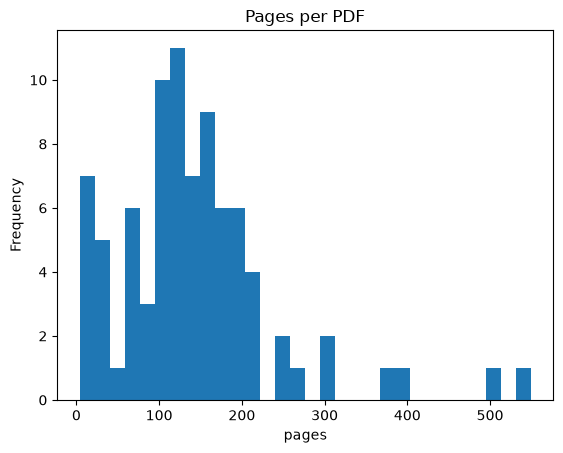

In [7]:
doc_names = sorted(df["doc_name"].unique())
page_counts = {}
for name in doc_names:
    with pymupdf.open(PDF_DIR / f"{name}.pdf") as doc:
        page_counts[name] = len(doc)
pages = pd.Series(page_counts).sort_values()

print(f"{len(pages)} PDFs, {pages.sum()} pages in total")
print(f"pages per PDF: min {pages.min()}, median {int(pages.median())}, max {pages.max()}")
print(f"shortest: {pages.index[0]} ({pages.iloc[0]} p), longest: {pages.index[-1]} ({pages.iloc[-1]} p)")
ax = pages.plot(kind="hist", bins=30, title="Pages per PDF")
ax.set_xlabel("pages")
plt.show()

Two properties of the data that might cause problems:

- some questions have evidence on more than one page, so top-1 retrieval can never fully cover them
- most companies have reports from several years in the corpus, so search can find the right table in the wrong year

In [8]:
print("evidence items per question:", dict(Counter(df["n_evidence"])))
print(f"{(df['n_evidence'] > 1).sum()} of {len(df)} questions have more than one evidence item\n")

docs_per_company = df.groupby("company")["doc_name"].nunique()
multi = docs_per_company[docs_per_company > 1]
print(f"{len(multi)} of {df['company'].nunique()} companies have more than one report in the corpus")
print(f"{df['company'].isin(multi.index).sum()} of {len(df)} questions are about such a company (wrong-year risk)")
multi.sort_values(ascending=False).head(10)

evidence items per question: {1: 115, 3: 4, 2: 31}
35 of 150 questions have more than one evidence item

26 of 32 companies have more than one report in the corpus
135 of 150 questions are about such a company (wrong-year risk)


company
PepsiCo              5
Amcor                5
MGM Resorts          5
Adobe                4
Nike                 4
Best Buy             4
Johnson & Johnson    4
JPMorgan             4
3M                   3
Corning              3
Name: doc_name, dtype: int64

## 3. Page numbering check

We check if the `evidence_text` is actually found in `evidence_page_num`, so that we can match the page indexing of the dataset to the our indexing with here. 

The texts are compared with all whitespace and punctuation removed so that matching is easier.

In [9]:
def squash(s: str) -> str:
    """Lowercase the text and keep only letters and digits, so spacing and punctuation differences don't matter."""
    return re.sub(r"[^a-z0-9]", "", s.lower())


docs = {name: pymupdf.open(PDF_DIR / f"{name}.pdf") for name in doc_names}

matched = 0
missed = []
for q in questions:
    doc = docs[q["doc_name"]]
    for ev in q["evidence"]:
        p = ev["evidence_page_num"]
        snippet = squash(ev["evidence_text"])[:60]
        if snippet in squash(doc[p].get_text()):
            matched += 1
        else:
            missed.append((q["financebench_id"], q["doc_name"], p))

print(f"{matched} of {matched + len(missed)} evidence items found on the page their evidence_page_num points to")
if missed:
    print("not found:", missed)

189 of 189 evidence items found on the page their evidence_page_num points to


Q: What is the FY2018 capital expenditure amount (in USD millions) for 3M? Give a response to the question by relying on the details shown in the cash flow statement.
A: $1577.00


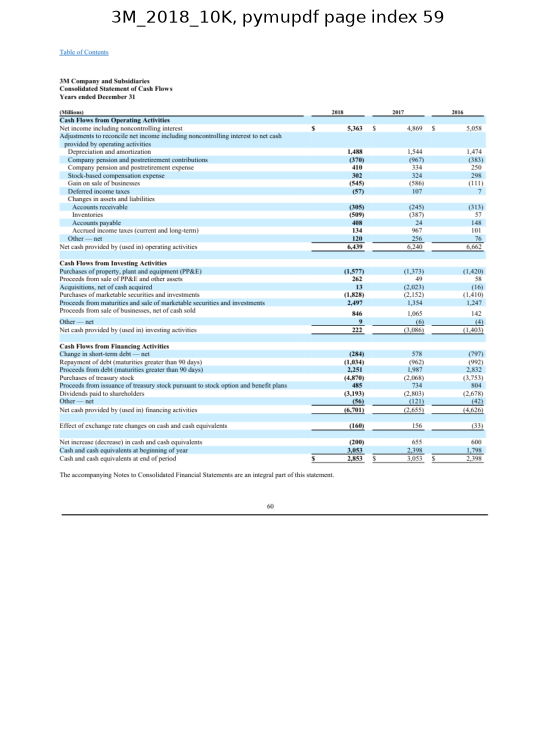

In [10]:
# visual check for a single question, by renering the evidence page as an image, with the question next to it

sample = df[df["financebench_id"] == "financebench_id_03029"].iloc[0]  # 3M FY2018 capex
page = docs[sample["doc_name"]][sample["evidence_pages"][0]]

print("Q:", sample["question"])
print("A:", sample["answer"])

pix = page.get_pixmap(dpi=100)
sanity_path = FIG_DIR / "_sanity_page.png"
pix.save(sanity_path)
fig, ax = plt.subplots(figsize=(7, 9))
ax.imshow(mpimg.imread(sanity_path))
ax.axis("off")
ax.set_title(f"{sample['doc_name']}, pymupdf page index {sample['evidence_pages'][0]}")
plt.show()

## 4. What extraction does to tables

The figure below shows the same page twice, once as the image a vision model would see and once as the text that PyMuPDF extracts. In the extracted text the numbers lose their row and column labels, which is the problem the whole text-or-image comparison is about.

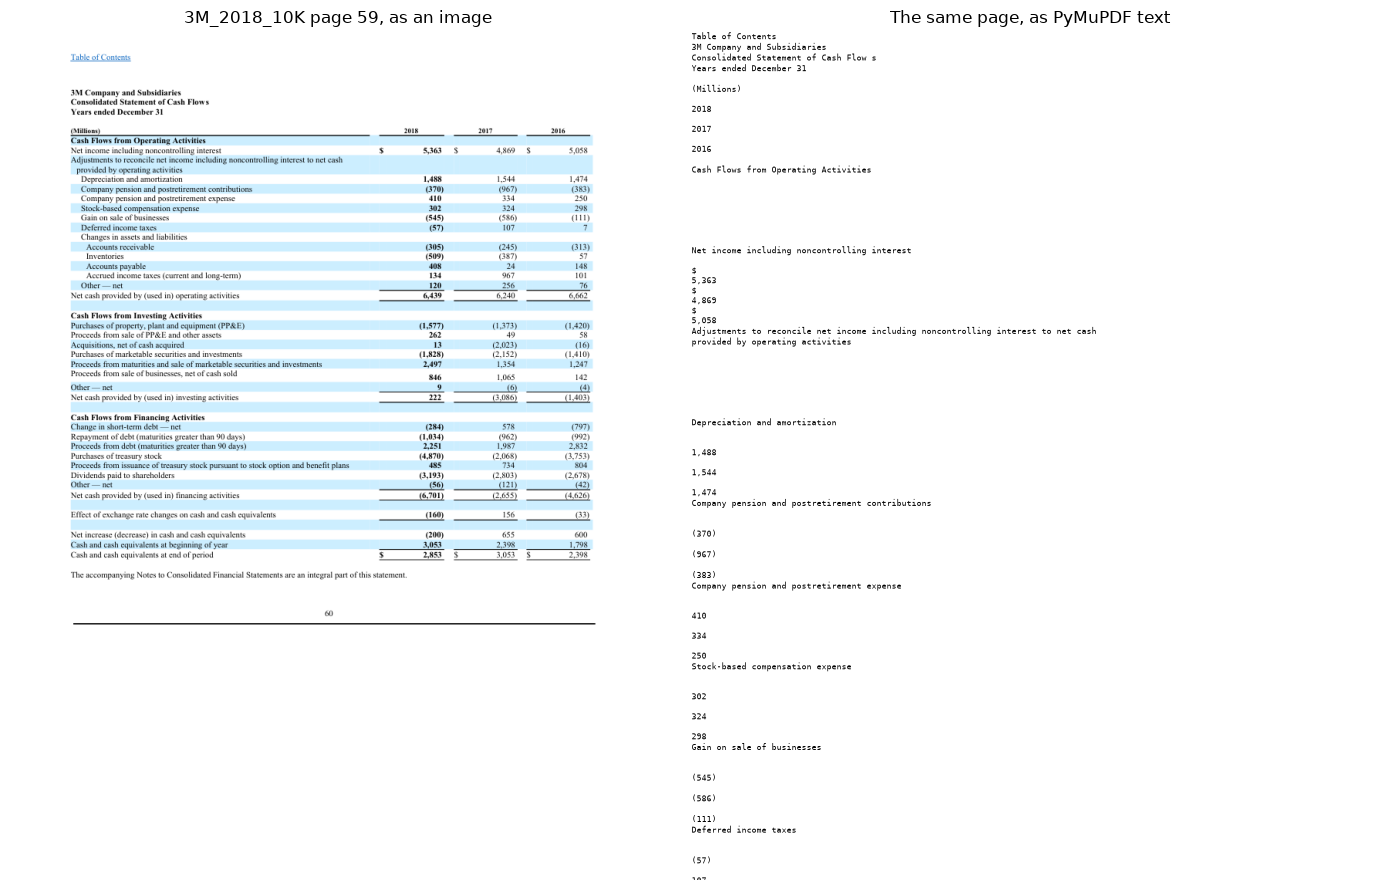

In [11]:
text = page.get_text()

fig, axes = plt.subplots(1, 2, figsize=(14, 9))
axes[0].imshow(mpimg.imread(sanity_path))
axes[0].axis("off")
axes[0].set_title(f"{sample['doc_name']} page {sample['evidence_pages'][0]}, as an image")
axes[1].text(0.0, 1.0, text[:1900], fontsize=6, va="top", family="monospace", clip_on=True)
axes[1].axis("off")
axes[1].set_title("The same page, as PyMuPDF text")
plt.tight_layout()
fig.savefig(FIG_DIR / "garbled_table.png", dpi=150, bbox_inches="tight")
plt.show()
#print("saved", FIG_DIR / "garbled_table.png")

## 5. Freeze the dev/test split

All tuning will happen on 30 dev questions.

The 120 test questions are used once, at the end, with frozen settings. The split is stratified with 10 questions per `question_type`, drawn with a fixed seed.

We save the split under `data/split.json`, so the split stays frozen across re-runs.

In [12]:
split_path = REPO / "data" / "split.json"

if split_path.exists():
    split = json.loads(split_path.read_text())
    print("data/split.json already exists, keeping it frozen")
else:
    rng = random.Random(SEED)
    dev_ids = []
    for qtype in sorted(df["question_type"].unique()):
        ids = sorted(df.loc[df["question_type"] == qtype, "financebench_id"])
        dev_ids += rng.sample(ids, 10)
    dev_ids = sorted(dev_ids)
    test_ids = sorted(set(df["financebench_id"]) - set(dev_ids))
    split = {
        "dataset": "FinanceBench open-source subset, 150 questions",
        "created": date.today().isoformat(),
        "seed": SEED,
        "method": "per question_type, ids sorted then random.Random(seed).sample(ids, 10) -> 30 dev, rest test",
        "n_dev": len(dev_ids),
        "n_test": len(test_ids),
        "dev": dev_ids,
        "test": test_ids,
    }
    split_path.write_text(json.dumps(split, indent=2) + "\n")
    print("wrote", split_path)

assert len(split["dev"]) == 30 and len(split["test"]) == 120 and not set(split["dev"]) & set(split["test"])

print("\ndev questions per question_type")
print(df[df["financebench_id"].isin(split["dev"])]["question_type"].value_counts())
print("\ndev questions per doc_type")
print(df[df["financebench_id"].isin(split["dev"])]["doc_type"].value_counts())

wrote /Users/dogamentese/financebench-rag/data/split.json

dev questions per question_type
question_type
metrics-generated    10
domain-relevant      10
novel-generated      10
Name: count, dtype: int64

dev questions per doc_type
doc_type
10k         24
Earnings     3
8k           2
10q          1
Name: count, dtype: int64
